<a href="https://colab.research.google.com/github/Suchi0012/CodeAlpha_DiseasePrediction/blob/main/CodeAlpha_CreditScoringModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

german_credit = fetch_ucirepo(id=144)

X = german_credit.data.features.copy()
y = german_credit.data.targets.copy()

df = pd.concat([X, y], axis=1)

print("Dataset Shape:", df.shape)
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

display(df.head())


Dataset Shape: (1000, 21)
Feature Shape: (1000, 20)
Target Shape: (1000, 1)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [3]:

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Attribute1   1000 non-null   object
 1   Attribute2   1000 non-null   int64 
 2   Attribute3   1000 non-null   object
 3   Attribute4   1000 non-null   object
 4   Attribute5   1000 non-null   int64 
 5   Attribute6   1000 non-null   object
 6   Attribute7   1000 non-null   object
 7   Attribute8   1000 non-null   int64 
 8   Attribute9   1000 non-null   object
 9   Attribute10  1000 non-null   object
 10  Attribute11  1000 non-null   int64 
 11  Attribute12  1000 non-null   object
 12  Attribute13  1000 non-null   int64 
 13  Attribute14  1000 non-null   object
 14  Attribute15  1000 non-null   object
 15  Attribute16  1000 non-null   int64 
 16  Attribute17  1000 non-null   object
 17  Attribute18  1000 non-null   int64 
 18  Attribute19  1000 non-null   object
 19  Attribu

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,class
count,1000,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000,1000,1000,...,1000,1000.000000,1000,1000,1000.000000,1000,1000.000000,1000,1000,1000.000000
unique,4,NaN,5,10,NaN,5,5,NaN,4,3,...,4,NaN,3,3,NaN,4,NaN,2,2,NaN
top,A14,NaN,A32,A43,NaN,A61,A73,NaN,A93,A101,...,A123,NaN,A143,A152,NaN,A173,NaN,A191,A201,NaN
freq,394,NaN,530,280,NaN,603,339,NaN,548,907,...,332,NaN,814,713,NaN,630,NaN,596,963,NaN
mean,NaN,20.903000,NaN,NaN,3271.258000,NaN,NaN,2.973000,NaN,NaN,...,NaN,35.546000,NaN,NaN,1.407000,NaN,1.155000,NaN,NaN,1.300000
std,NaN,12.058814,NaN,NaN,2822.736876,NaN,NaN,1.118715,NaN,NaN,...,NaN,11.375469,NaN,NaN,0.577654,NaN,0.362086,NaN,NaN,0.458487
min,NaN,4.000000,NaN,NaN,250.000000,NaN,NaN,1.000000,NaN,NaN,...,NaN,19.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,1.000000
25%,NaN,12.000000,NaN,NaN,1365.500000,NaN,NaN,2.000000,NaN,NaN,...,NaN,27.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,1.000000
50%,NaN,18.000000,NaN,NaN,2319.500000,NaN,NaN,3.000000,NaN,NaN,...,NaN,33.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,1.000000
75%,NaN,24.000000,NaN,NaN,3972.250000,NaN,NaN,4.000000,NaN,NaN,...,NaN,42.000000,NaN,NaN,2.000000,NaN,1.000000,NaN,NaN,2.000000


In [4]:

print("Total Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nCredit Risk Distribution:")
print(df["class"].value_counts())


Total Missing Values:
0

Duplicate Rows:
0

Credit Risk Distribution:
class
1    700
2    300
Name: count, dtype: int64


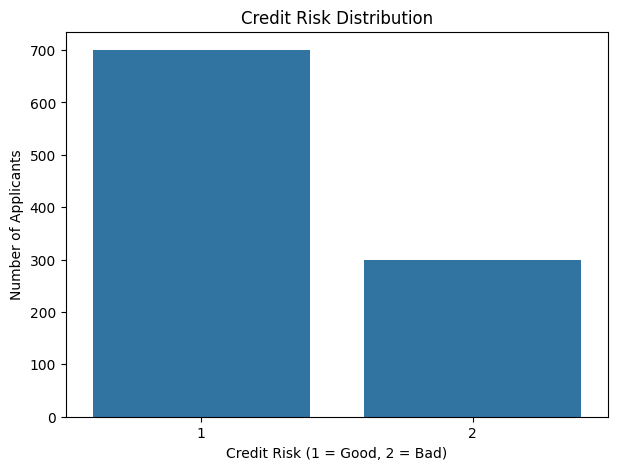

In [5]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="class"
)

plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk (1 = Good, 2 = Bad)")
plt.ylabel("Number of Applicants")

plt.show()


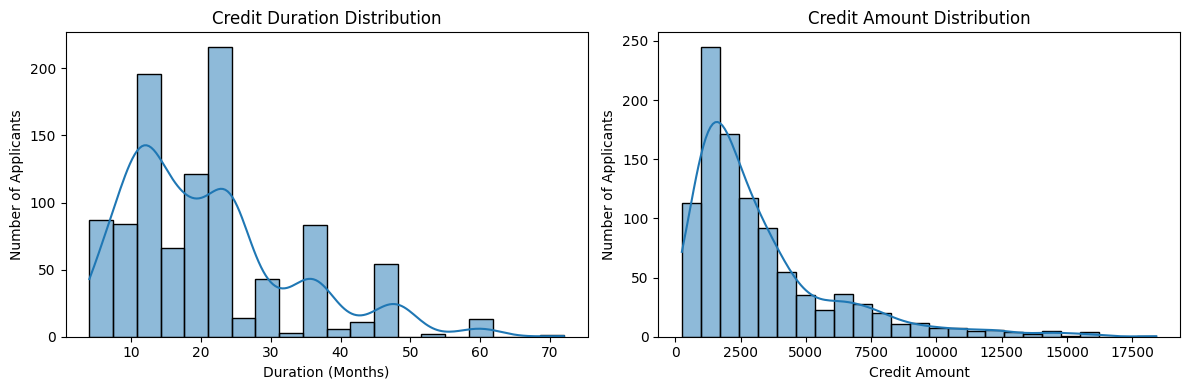

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=df,
    x="Attribute2",
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Credit Duration Distribution")
axes[0].set_xlabel("Duration (Months)")
axes[0].set_ylabel("Number of Applicants")

sns.histplot(
    data=df,
    x="Attribute5",
    bins=25,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Credit Amount Distribution")
axes[1].set_xlabel("Credit Amount")
axes[1].set_ylabel("Number of Applicants")

plt.tight_layout()
plt.show()


In [7]:
df_model = df.copy()

df_model["Credit_per_Month"] = (
    df_model["Attribute5"] / df_model["Attribute2"]
)

df_model["Risk"] = df_model["class"].map({1: 0, 2: 1})

df_model = df_model.drop(columns=["class"])

print("New Dataset Shape:", df_model.shape)

display(
    df_model[
        ["Attribute2", "Attribute5", "Credit_per_Month", "Risk"]
    ].head()
)


New Dataset Shape: (1000, 22)


,Attribute2,Attribute5,Credit_per_Month,Risk
0,6,1169,194.833333,0
1,48,5951,123.979167,1
2,12,2096,174.666667,0
3,42,7882,187.666667,0
4,24,4870,202.916667,1


In [8]:
X = df_model.drop(columns=["Risk"])
y = df_model["Risk"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Features Shape: (1000, 21)
Target Shape: (1000,)

Target Distribution:
Risk
0    700
1    300
Name: count, dtype: int64


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Features: (800, 21)
Testing Features: (200, 21)

Training Target Distribution:
Risk
0    560
1    240
Name: count, dtype: int64

Testing Target Distribution:
Risk
0    140
1     60
Name: count, dtype: int64


In [10]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

print("Categorical Features:", len(categorical_cols))
print("Numerical Features:", len(numerical_cols))

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore",
                              sparse_output=False), categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing completed successfully!")
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)


Categorical Features: 13
Numerical Features: 8

Preprocessing completed successfully!
Processed Training Shape: (800, 62)
Processed Testing Shape: (200, 62)


In [11]:
print("Missing values in training data:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing data:",
      np.isnan(X_test_processed).sum())

print("\nFirst 5 rows of processed training data:")
display(pd.DataFrame(X_train_processed).head())


Missing values in training data: 0
Missing values in testing data: 0

First 5 rows of processed training data:


,0,1,2,3,4,5,6,7,8,9,...,52,53,54,55,56,57,58,59,60,61
0,1.289592,1.925766,0.052281,1.053413,1.057784,-0.718745,-0.436436,0.592795,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,-0.742595,-0.892853,0.942164,1.053413,0.242449,-0.718745,-0.436436,-0.820980,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,1.289592,0.816433,0.052281,-0.747293,-0.663479,1.045047,-0.436436,-0.114689,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,1.289592,0.299568,0.052281,-0.747293,-0.572886,-0.718745,-0.436436,-0.444323,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,2.305686,1.982655,-1.727486,-0.747293,-1.025850,-0.718745,-0.436436,0.122631,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [12]:

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

lr_pred = lr_model.predict(X_test_processed)

lr_prob = lr_model.predict_proba(X_test_processed)[:, 1]

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Logistic Regression Results")

print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall:", recall_score(y_test, lr_pred))
print("F1-Score:", f1_score(y_test, lr_pred))
print("ROC-AUC:", roc_auc_score(y_test, lr_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_pred,
    target_names=["Good Credit Risk", "Bad Credit Risk"]
))


Logistic Regression Results
Accuracy: 0.785
Precision: 0.673469387755102
Recall: 0.55
F1-Score: 0.6055045871559633
ROC-AUC: 0.8057142857142857

Classification Report:
                  precision    recall  f1-score   support

Good Credit Risk       0.82      0.89      0.85       140
 Bad Credit Risk       0.67      0.55      0.61        60

        accuracy                           0.79       200
       macro avg       0.75      0.72      0.73       200
    weighted avg       0.78      0.79      0.78       200



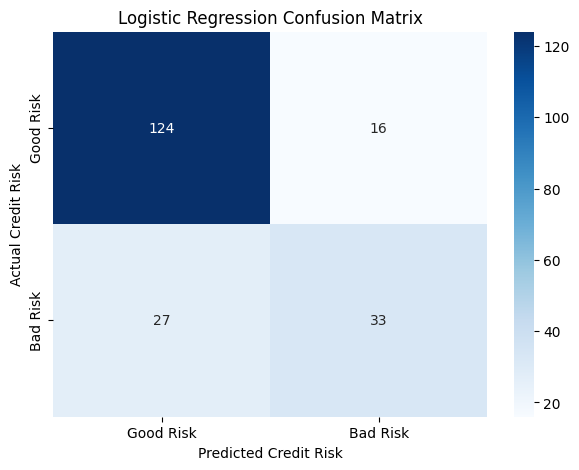

In [14]:
cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Good Risk", "Bad Risk"],
    yticklabels=["Good Risk", "Bad Risk"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Credit Risk")
plt.ylabel("Actual Credit Risk")

plt.show()


In [15]:

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

dt_pred = dt_model.predict(X_test_processed)

dt_prob = dt_model.predict_proba(X_test_processed)[:, 1]

print("Decision Tree Model Trained Successfully!")


Decision Tree Model Trained Successfully!


In [16]:
print("Decision Tree Results")

print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1-Score:", f1_score(y_test, dt_pred))
print("ROC-AUC:", roc_auc_score(y_test, dt_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=["Good Credit Risk", "Bad Credit Risk"]
))


Decision Tree Results
Accuracy: 0.725
Precision: 0.5714285714285714
Recall: 0.3333333333333333
F1-Score: 0.42105263157894735
ROC-AUC: 0.6858928571428572

Classification Report:
                  precision    recall  f1-score   support

Good Credit Risk       0.76      0.89      0.82       140
 Bad Credit Risk       0.57      0.33      0.42        60

        accuracy                           0.72       200
       macro avg       0.66      0.61      0.62       200
    weighted avg       0.70      0.72      0.70       200



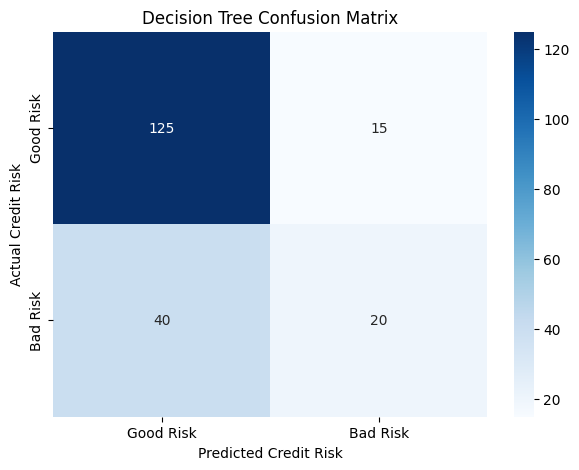

In [17]:

cm_dt = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Good Risk", "Bad Risk"],
    yticklabels=["Good Risk", "Bad Risk"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Credit Risk")
plt.ylabel("Actual Credit Risk")

plt.show()


In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)

rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [19]:

print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1-Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Good Credit Risk", "Bad Credit Risk"]
))


Random Forest Results
Accuracy: 0.765
Precision: 0.696969696969697
Recall: 0.38333333333333336
F1-Score: 0.4946236559139785
ROC-AUC: 0.7927380952380952

Classification Report:
                  precision    recall  f1-score   support

Good Credit Risk       0.78      0.93      0.85       140
 Bad Credit Risk       0.70      0.38      0.49        60

        accuracy                           0.77       200
       macro avg       0.74      0.66      0.67       200
    weighted avg       0.75      0.77      0.74       200



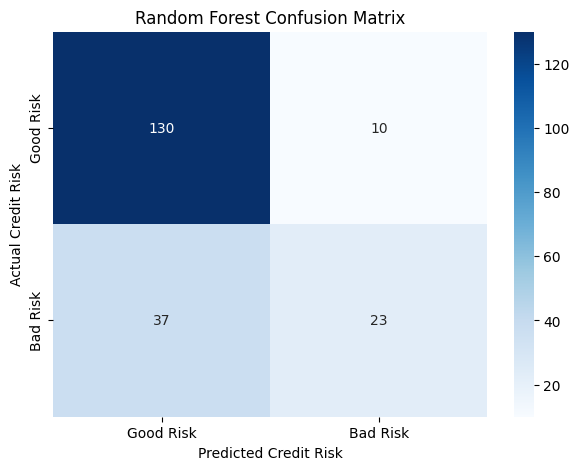

In [20]:


cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Good Risk", "Bad Risk"],
    yticklabels=["Good Risk", "Bad Risk"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Credit Risk")
plt.ylabel("Actual Credit Risk")

plt.show()


In [21]:


models = {
    "Logistic Regression": (lr_pred, lr_prob),
    "Decision Tree": (dt_pred, dt_prob),
    "Random Forest": (rf_pred, rf_prob)
}

results = []

for name, (pred, prob) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.785,0.6735,0.5500,0.6055,0.8057
1,Decision Tree,0.725,0.5714,0.3333,0.4211,0.6859
2,Random Forest,0.765,0.6970,0.3833,0.4946,0.7927


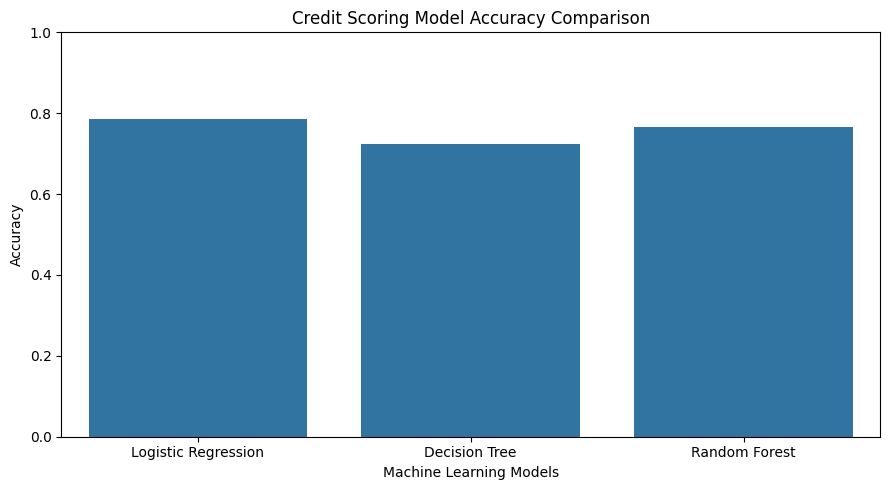

In [22]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Credit Scoring Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


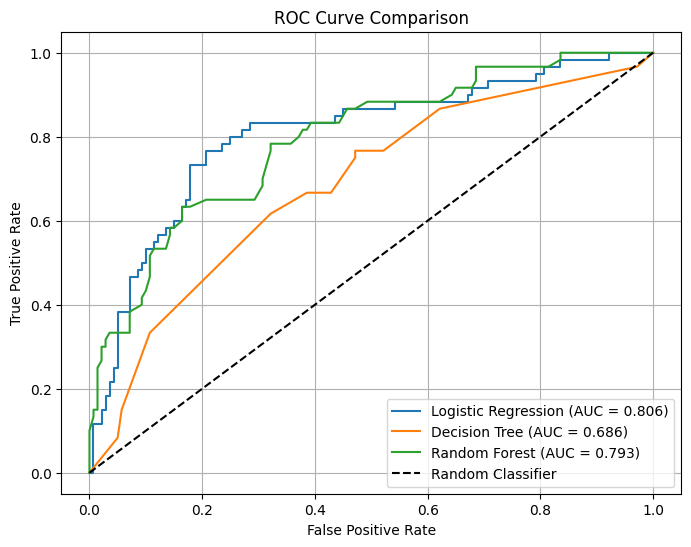

In [23]:


from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for name, (pred, prob) in models.items():
    fpr, tpr, thresholds = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.show()


In [24]:


import joblib
from sklearn.pipeline import Pipeline
from sklearn.base import clone

credit_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", clone(lr_model))
])

credit_model.fit(X_train, y_train)

pipeline_predictions = credit_model.predict(X_test)

print(
    "Predictions match original model:",
    np.array_equal(pipeline_predictions, lr_pred)
)

joblib.dump(credit_model, "credit_scoring_model.pkl")

print("Credit Scoring Model Saved Successfully!")


Predictions match original model: True
Credit Scoring Model Saved Successfully!


In [25]:
new_applicant = X_test.iloc[[0]]

prediction = credit_model.predict(new_applicant)

risk_probability = credit_model.predict_proba(new_applicant)[0, 1]

if prediction[0] == 0:
    print("Prediction: Good Credit Risk")
else:
    print("Prediction: Bad Credit Risk")

print(f"Estimated Bad Risk Probability: {risk_probability:.2%}")
print("Actual Risk Class:", y_test.iloc[0])


Prediction: Good Credit Risk
Estimated Bad Risk Probability: 22.76%
Actual Risk Class: 0


In [26]:

%%writefile requirements.txt
numpy
pandas
matplotlib
seaborn
scikit-learn
joblib
ucimlrepo


Writing requirements.txt


In [27]:

import os

print(os.listdir())


['.config', 'requirements.txt', 'credit_scoring_model.pkl', 'sample_data']
